# Week 1 Advancement Task
## Capacity, Fourier support, and finite-shot robustness in a re-uploading QNN

**Student:** Rana Muhammad Hamza  
**Roll number:** 25280103  
**Course:** QML  
**Project:** Data Re-Uploading and the Fourier Spectrum of QNNs

This reproducible extension uses the saved Week 1 input file, extends the one-qubit layer sweep from L=1-3 to L=1-6, introduces a known high-harmonic challenge target, checks the measured Fourier support on two grid resolutions, and quantifies finite-shot error. It uses exact NumPy statevectors; shot noise is added by sampling the corresponding Pauli-Z measurement distribution. It makes no hardware claim.


## 1. Research question, hypothesis, and falsifier

**Question.** As data re-uploading grows from one to six layers, how do dense-grid fit error and the learned Fourier spectrum change on (a) the original Week 1 periodic target and (b) a controlled target containing harmonics 1, 4, and 6? Does a support-matched Fourier linear model provide a useful reference, and how does finite-shot sampling affect a trained model?

**Hypothesis.** With one RY(x) encoding per layer, the noiseless one-qubit expectation has candidate integer modes only within |k| <= L. Increasing L expands the candidate support but does not guarantee a better optimizer result. The six-layer circuit can represent the new sixth harmonic, while lower-depth circuits cannot. Finite-shot error should decrease as the shot budget increases.

**Falsifier.** A trained noiseless QNN with a reproducible coefficient above max(1e-6, 0.01 times the largest coefficient) outside |k| <= L at both 256- and 512-point grids would falsify the tested support prediction. A repeated six-layer fit that cannot reduce the high-harmonic target's MSE below the lower-layer fits would count against the optimization part of the hypothesis, but not by itself against the representational support theorem.

The thresholds, data, seeds, grids, and optimizer are locked below before model results are calculated.


## 2. Data, protocol, and classical comparison

The original x samples and 256-point evaluation grid are loaded from `outputs/week1/week1_inputs_and_fixed_folds.npz`; the notebook does not redraw them. The second target is evaluated on those same x locations so that only the target spectrum changes:

f_high(x) = 0.35 cos(x) + 0.25 sin(4x) + 0.20 cos(6x).

Both targets use five independent initialization seeds (0-4), full-batch Adam, learning rate 0.01, and at most 1,000 updates. The comparison baseline is a least-squares Fourier model with exactly 2L sine/cosine parameters, matching the QNN's 2L trainable angles. QNN spectrum checks use both 256 and 512 uniform points over [-pi, pi).


In [1]:
from __future__ import annotations

import json
import math
import platform
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn

ROOT = Path.cwd()
SOURCE_NPZ = ROOT / "outputs" / "week1" / "week1_inputs_and_fixed_folds.npz"
OUT = ROOT / "outputs" / "week1Advancement"
FIG = OUT / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

SEED = 42
INITIALIZATION_SEEDS = tuple(range(5))
LAYERS = tuple(range(1, 7))
LEARNING_RATE = 0.01
MAX_STEPS = 1000
SPECTRUM_THRESHOLD_RELATIVE = 0.01
SPECTRUM_THRESHOLD_ABSOLUTE = 1e-6

bundle = np.load(SOURCE_NPZ, allow_pickle=False)
x_train = bundle["X_1d_train"].reshape(-1)
y_original_train = bundle["y_1d_train"].reshape(-1)
x_grid = bundle["X_1d_grid"].reshape(-1)
y_original_grid = bundle["y_1d_grid"].reshape(-1)
x_grid_512 = np.linspace(-np.pi, np.pi, 512, endpoint=False)

def f_high(x):
    x = np.asarray(x, dtype=float)
    return 0.35 * np.cos(x) + 0.25 * np.sin(4 * x) + 0.20 * np.cos(6 * x)

y_high_train = f_high(x_train)
y_high_grid = f_high(x_grid)
y_high_grid_512 = f_high(x_grid_512)

print("Loaded Week 1 data:", SOURCE_NPZ)
print("Original training/grid:", x_train.shape, x_grid.shape)
print("New high-harmonic target support: k = +/-1, +/-4, +/-6")
print("Seeds:", INITIALIZATION_SEEDS, "| layer counts:", LAYERS)
print("Python", platform.python_version(), "NumPy", np.__version__, "pandas", pd.__version__)


Loaded Week 1 data: C:\Users\Teacher\Desktop\qml\qnn-fourier-spectrum\outputs\week1\week1_inputs_and_fixed_folds.npz
Original training/grid: (128,) (256,)
New high-harmonic target support: k = +/-1, +/-4, +/-6
Seeds: (0, 1, 2, 3, 4) | layer counts: (1, 2, 3, 4, 5, 6)
Python 3.13.7 NumPy 2.5.5 pandas 2.3.3


## 3. Circuit and training method

Each layer applies the data gate RY(x), then trainable RZ(theta_z) and RY(theta_y). The measured output is the exact expectation value of Z from a two-amplitude NumPy statevector. Each trainable angle occurs once as a Pauli rotation, so its MSE derivative is computed with the exact parameter-shift rule. The circuit uses one qubit, 3L single-qubit gates per evaluation, 2L trainable angles, no two-qubit gates, and a 2^1=2 dimensional statevector.

An RX(x) data-gate ablation is trained at L=6 on the high-harmonic target with the same seeds and optimizer. This checks whether the encoding axis changes optimization while leaving the layer-count support bound unchanged.


In [2]:
I2 = np.eye(2, dtype=complex)
Z = np.diag([1.0, -1.0]).astype(complex)

def ry(angle):
    c, s = math.cos(angle / 2), math.sin(angle / 2)
    return np.array([[c, -s], [s, c]], dtype=complex)

def rz(angle):
    return np.diag([np.exp(-0.5j * angle), np.exp(0.5j * angle)])

def rx_data_batch(x, axis="RY"):
    x = np.asarray(x, dtype=float).reshape(-1)
    c, s = np.cos(x / 2), np.sin(x / 2)
    result = np.zeros((len(x), 2, 2), dtype=complex)
    if axis.upper() == "RY":
        result[:, 0, 0] = c; result[:, 0, 1] = -s
        result[:, 1, 0] = s; result[:, 1, 1] = c
    elif axis.upper() == "RX":
        result[:, 0, 0] = c; result[:, 0, 1] = -1j * s
        result[:, 1, 0] = -1j * s; result[:, 1, 1] = c
    else:
        raise ValueError("axis must be RY or RX")
    return result

def predict_qnn_batch(x, theta_batch, data_axis="RY"):
    x = np.asarray(x, dtype=float).reshape(-1)
    theta_batch = np.asarray(theta_batch, dtype=float)
    if theta_batch.ndim == 1:
        theta_batch = theta_batch[None, :]
    if theta_batch.shape[1] % 2:
        raise ValueError("There must be two trainable angles per layer")
    state = np.zeros((len(theta_batch), len(x), 2), dtype=complex)
    state[:, :, 0] = 1.0
    data_gates = rx_data_batch(x, data_axis)
    for layer in range(theta_batch.shape[1] // 2):
        state = np.einsum("nij,bnj->bni", data_gates, state, optimize=True)
        z_angle = theta_batch[:, 2 * layer]
        phase0 = np.exp(-0.5j * z_angle)[:, None]
        phase1 = np.exp(0.5j * z_angle)[:, None]
        state[:, :, 0] *= phase0
        state[:, :, 1] *= phase1
        y_angle = theta_batch[:, 2 * layer + 1]
        c = np.cos(y_angle / 2)[:, None]
        s = np.sin(y_angle / 2)[:, None]
        old0 = state[:, :, 0].copy()
        old1 = state[:, :, 1].copy()
        state[:, :, 0] = c * old0 - s * old1
        state[:, :, 1] = s * old0 + c * old1
    return np.real(np.abs(state[:, :, 0]) ** 2 - np.abs(state[:, :, 1]) ** 2)

def predict_qnn(x, theta, data_axis="RY"):
    return predict_qnn_batch(x, np.asarray(theta)[None, :], data_axis)[0]

def fit_qnn(x, y, layers, seed, data_axis="RY", steps=MAX_STEPS, learning_rate=LEARNING_RATE):
    # Identical initialization stream across RY/RX makes the gate-axis ablation paired.
    rng = np.random.default_rng(SEED + 1000 * layers + seed)
    theta = rng.normal(0.0, 0.25, size=2 * layers)
    m = np.zeros_like(theta); v = np.zeros_like(theta)
    best_theta = theta.copy()
    best_loss = float("inf")
    beta1, beta2, eps = 0.9, 0.999, 1e-8
    for step in range(1, steps + 1):
        shifted = np.repeat(theta[None, :], 1 + 2 * len(theta), axis=0)
        for j in range(len(theta)):
            shifted[1 + 2*j, j] += np.pi / 2
            shifted[2 + 2*j, j] -= np.pi / 2
        shifted_predictions = predict_qnn_batch(x, shifted, data_axis)
        pred = shifted_predictions[0]
        residual = pred - y
        loss = float(np.mean(residual ** 2))
        if loss < best_loss:
            best_loss, best_theta = loss, theta.copy()
        d_expectation = (shifted_predictions[1::2] - shifted_predictions[2::2]) / 2
        gradient = 2 * np.mean(d_expectation * residual[None, :], axis=1)
        m = beta1 * m + (1 - beta1) * gradient
        v = beta2 * v + (1 - beta2) * (gradient ** 2)
        m_hat = m / (1 - beta1 ** step)
        v_hat = v / (1 - beta2 ** step)
        theta -= learning_rate * m_hat / (np.sqrt(v_hat) + eps)
    final_loss = float(np.mean((predict_qnn(x, theta, data_axis) - y) ** 2))
    if final_loss < best_loss:
        best_loss, best_theta = final_loss, theta.copy()
    return best_theta, best_loss

print("Circuit API ready: one qubit; data gate RY; trainable gates RZ then RY; observable Z.")


Circuit API ready: one qubit; data gate RY; trainable gates RZ then RY; observable Z.


## 4. Support-matched Fourier reference and spectrum metrics

For each layer count L, the classical reference fits sine and cosine coefficients for harmonics 1 through L, with 2L parameters and no intercept. A coefficient is counted as present only when its magnitude exceeds max(1e-6, 0.01*c_max). The outside-support count and maximum outside-support magnitude are measured independently on 256- and 512-point grids to check for discretization or aliasing artifacts.


In [3]:
def fourier_design(x, max_harmonic):
    x = np.asarray(x, dtype=float).reshape(-1)
    return np.column_stack([
        f(x)
        for k in range(1, max_harmonic + 1)
        for f in (lambda z, k=k: np.cos(k * z), lambda z, k=k: np.sin(k * z))
    ])

def fit_fourier(x, y, max_harmonic):
    design = fourier_design(x, max_harmonic)
    coef, *_ = np.linalg.lstsq(design, np.asarray(y), rcond=None)
    return coef

def predict_fourier(x, coef):
    return fourier_design(x, len(coef) // 2) @ coef

def spectrum_summary(values, max_allowed):
    values = np.asarray(values, dtype=float).reshape(-1)
    coeff = np.fft.fftshift(np.fft.fft(values) / len(values))
    modes = np.rint(np.fft.fftshift(np.fft.fftfreq(len(values), d=1 / len(values)))).astype(int)
    magnitudes = np.abs(coeff)
    threshold = max(SPECTRUM_THRESHOLD_ABSOLUTE, SPECTRUM_THRESHOLD_RELATIVE * float(magnitudes.max()))
    active = magnitudes > threshold
    outside = active & (np.abs(modes) > max_allowed)
    return {
        "threshold": threshold,
        "active_modes": modes[active],
        "outside_count": int(outside.sum()),
        "max_outside_magnitude": float(magnitudes[outside].max()) if outside.any() else 0.0,
        "max_mode": int(np.max(np.abs(modes[active]))) if active.any() else 0,
        "modes": modes,
        "magnitudes": magnitudes,
    }

print("Fourier support threshold:", SPECTRUM_THRESHOLD_ABSOLUTE, "absolute or", SPECTRUM_THRESHOLD_RELATIVE, "of c_max")


Fourier support threshold: 1e-06 absolute or 0.01 of c_max


## 5. Run the preregistered L=1-6 sweep

The same saved 128 training inputs and 256-point dense grid are used for both targets. Five initialization seeds are run at every depth. Per-model predictions, training error, evaluation error, support metrics, training duration, and parameter count are stored immediately so the result is auditable.


In [4]:
targets = {
    "week1_original": (y_original_train, y_original_grid, y_original_grid),
    "high_harmonic": (y_high_train, y_high_grid, y_high_grid_512),
}
grid_by_target = {
    "week1_original": (x_grid, x_grid_512),
    "high_harmonic": (x_grid, x_grid_512),
}

run_rows = []
predictions = {}
started_all = time.time()
progress_path = OUT / "advancement_progress.csv"
for target_name, (y_train_target, y_eval_target, _) in targets.items():
    grid256, grid512 = grid_by_target[target_name]
    target512 = y_original_grid if target_name == "week1_original" else y_high_grid_512
    for layers in LAYERS:
        baseline_coef = fit_fourier(x_train, y_train_target, layers)
        baseline_prediction = predict_fourier(grid256, baseline_coef)
        baseline_mse = float(np.mean((baseline_prediction - y_eval_target) ** 2))
        for seed in INITIALIZATION_SEEDS:
            t0 = time.time()
            theta, train_mse = fit_qnn(x_train, y_train_target, layers, seed)
            pred256 = predict_qnn(grid256, theta)
            pred512 = predict_qnn(grid512, theta)
            spectrum256 = spectrum_summary(pred256, layers)
            spectrum512 = spectrum_summary(pred512, layers)
            key = f"{target_name}_L{layers}_seed{seed}"
            predictions[key + "_grid256"] = pred256
            predictions[key + "_grid512"] = pred512
            predictions[key + "_theta"] = theta
            run_rows.append({
                "target": target_name,
                "layers": layers,
                "seed": seed,
                "parameters": 2 * layers,
                "train_mse": train_mse,
                "grid_mse": float(np.mean((pred256 - y_eval_target) ** 2)),
                "fourier_KL_mse": baseline_mse,
                "grid256_outside_count": spectrum256["outside_count"],
                "grid512_outside_count": spectrum512["outside_count"],
                "grid256_max_outside_magnitude": spectrum256["max_outside_magnitude"],
                "grid512_max_outside_magnitude": spectrum512["max_outside_magnitude"],
                "grid256_max_active_mode": spectrum256["max_mode"],
                "grid512_max_active_mode": spectrum512["max_mode"],
                "fit_seconds": time.time() - t0,
            })
            pd.DataFrame(run_rows).to_csv(progress_path, index=False)
            print(f"{target_name:16s} L={layers} seed={seed}: train MSE={train_mse:.6g}, grid MSE={run_rows[-1]['grid_mse']:.6g}, {time.time()-t0:.1f}s", flush=True)

run_df = pd.DataFrame(run_rows)
run_df.to_csv(OUT / "advancement_layer_sweep.csv", index=False)
np.savez_compressed(OUT / "advancement_predictions_parameters.npz", **predictions)
print(f"Completed {len(run_df)} fits in {(time.time()-started_all)/60:.1f} min")


week1_original   L=1 seed=0: train MSE=0.0519349, grid MSE=0.065933, 0.3s


week1_original   L=1 seed=1: train MSE=0.0519349, grid MSE=0.065933, 0.3s


week1_original   L=1 seed=2: train MSE=0.0519349, grid MSE=0.065933, 0.2s


week1_original   L=1 seed=3: train MSE=0.0519349, grid MSE=0.065933, 0.2s


week1_original   L=1 seed=4: train MSE=0.0519349, grid MSE=0.065933, 0.3s


week1_original   L=2 seed=0: train MSE=0.152356, grid MSE=0.146734, 0.5s


... (51 outputs left out)

high_harmonic    L=6 seed=2: train MSE=0.00186394, grid MSE=0.00169291, 3.4s


high_harmonic    L=6 seed=3: train MSE=0.0207178, grid MSE=0.0216075, 3.4s


high_harmonic    L=6 seed=4: train MSE=0.0101877, grid MSE=0.011376, 2.5s


Completed 60 fits in 1.7 min


## 6. Gate-axis ablation at six layers

The RX(x) variant keeps the same one-qubit width, number of layers, number of trainable angles, and optimizer. Only the data-encoding Pauli axis changes. This is an ablation of the encoding and optimization path, not a claim that the two gates have different theoretical frequency cutoffs.


In [5]:
axis_rows = []
axis_predictions = {}
for axis in ("RY", "RX"):
    for seed in INITIALIZATION_SEEDS:
        t0 = time.time()
        theta, train_mse = fit_qnn(x_train, y_high_train, layers=6, seed=seed, data_axis=axis)
        pred256 = predict_qnn(x_grid, theta, data_axis=axis)
        pred512 = predict_qnn(x_grid_512, theta, data_axis=axis)
        s256 = spectrum_summary(pred256, 6)
        s512 = spectrum_summary(pred512, 6)
        axis_predictions[f"{axis}_seed{seed}_grid256"] = pred256
        axis_rows.append({
            "target": "high_harmonic", "data_axis": axis, "layers": 6, "seed": seed,
            "parameters": 12, "train_mse": train_mse,
            "grid_mse": float(np.mean((pred256 - y_high_grid) ** 2)),
            "grid256_outside_count": s256["outside_count"],
            "grid512_outside_count": s512["outside_count"],
            "fit_seconds": time.time() - t0,
        })
        print(f"axis={axis} seed={seed}: grid MSE={axis_rows[-1]['grid_mse']:.6g}", flush=True)
axis_df = pd.DataFrame(axis_rows)
axis_df.to_csv(OUT / "advancement_gate_axis_ablation.csv", index=False)
np.savez_compressed(OUT / "advancement_gate_axis_predictions.npz", **axis_predictions)


axis=RY seed=0: grid MSE=0.00387697


axis=RY seed=1: grid MSE=0.0115679


axis=RY seed=2: grid MSE=0.00169291


axis=RY seed=3: grid MSE=0.0216075


axis=RY seed=4: grid MSE=0.011376


axis=RX seed=0: grid MSE=6.42872e-05


axis=RX seed=1: grid MSE=9.85484e-06


axis=RX seed=2: grid MSE=0.000445413


axis=RX seed=3: grid MSE=0.00639722


axis=RX seed=4: grid MSE=0.006921


## 7. Finite-shot measurement robustness

The exact simulator supplies the ideal expectation p(+1)=(1+<Z>)/2. Independent binomial draws emulate repeated Z measurements without inserting a hardware noise channel. This isolates shot noise from gate noise. The comparison uses representative trained L=3/original and L=6/high-harmonic models, 64 evenly spaced inputs, 20 independent repetitions, and 128, 512, and 2,048 shots per input. These are simulated samples, not hardware executions.


In [6]:
rng_shots = np.random.default_rng(SEED + 9100)
shot_grid = np.linspace(-np.pi, np.pi, 64, endpoint=False)
shot_rows = []
representatives = [
    ("week1_original", 3, 0, y_original_grid),
    ("high_harmonic", 6, 0, y_high_grid),
]
for target_name, layers, seed, _ in representatives:
    key = f"{target_name}_L{layers}_seed{seed}_theta"
    theta = predictions[key]
    target = y_original_grid if target_name == "week1_original" else y_high_grid
    grid_ref = x_grid
    exact_grid = predict_qnn(grid_ref, theta)
    exact_on_shot_grid = np.interp(shot_grid, grid_ref, exact_grid, period=2*np.pi)
    target_on_shot_grid = np.interp(shot_grid, grid_ref, target, period=2*np.pi)
    p_plus = np.clip((1 + exact_on_shot_grid) / 2, 0, 1)
    for shots in (128, 512, 2048):
        for repeat in range(20):
            counts = rng_shots.binomial(shots, p_plus)
            sampled = 2 * counts / shots - 1
            shot_rows.append({
                "target": target_name, "layers": layers, "seed": seed,
                "shots_per_input": shots, "repeat": repeat,
                "sampled_prediction_mse_to_exact": float(np.mean((sampled - exact_on_shot_grid) ** 2)),
                "sampled_prediction_mse_to_target": float(np.mean((sampled - target_on_shot_grid) ** 2)),
            })
shot_df = pd.DataFrame(shot_rows)
shot_df.to_csv(OUT / "advancement_finite_shot_repeats.csv", index=False)
shot_summary = shot_df.groupby(["target", "layers", "shots_per_input"], as_index=False).agg(
    mse_exact_mean=("sampled_prediction_mse_to_exact", "mean"),
    mse_exact_sd=("sampled_prediction_mse_to_exact", "std"),
    mse_target_mean=("sampled_prediction_mse_to_target", "mean"),
    mse_target_sd=("sampled_prediction_mse_to_target", "std"),
)
shot_summary.to_csv(OUT / "advancement_finite_shot_summary.csv", index=False)
print(shot_summary.to_string(index=False))


        target  layers  shots_per_input  mse_exact_mean  mse_exact_sd  mse_target_mean  mse_target_sd
 high_harmonic       6              128        0.007014      0.001119         0.010794       0.001467
 high_harmonic       6              512        0.001692      0.000263         0.005268       0.000838
 high_harmonic       6             2048        0.000429      0.000075         0.004294       0.000318
week1_original       3              128        0.005250      0.000940         0.019848       0.001752
week1_original       3              512        0.001329      0.000240         0.016353       0.000889
week1_original       3             2048        0.000332      0.000065         0.015259       0.000332


## 8. Summaries, figures, and resource counts

The final tables report mean and standard deviation over five initialization seeds. Resource counts are architecture-derived gate counts for the noiseless one-qubit circuit. Fit quality and representational support are reported separately: support is a necessary architectural allowance, not a promise that optimization will learn each allowed coefficient.


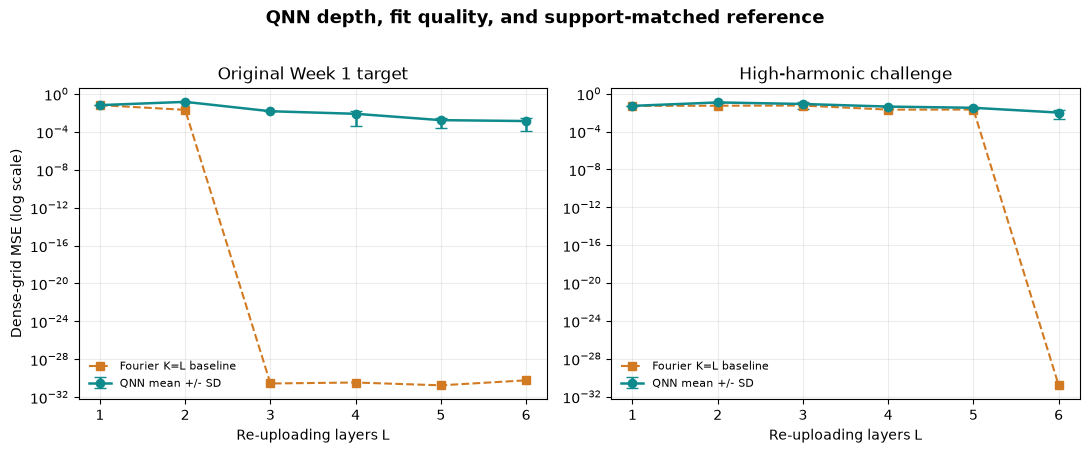

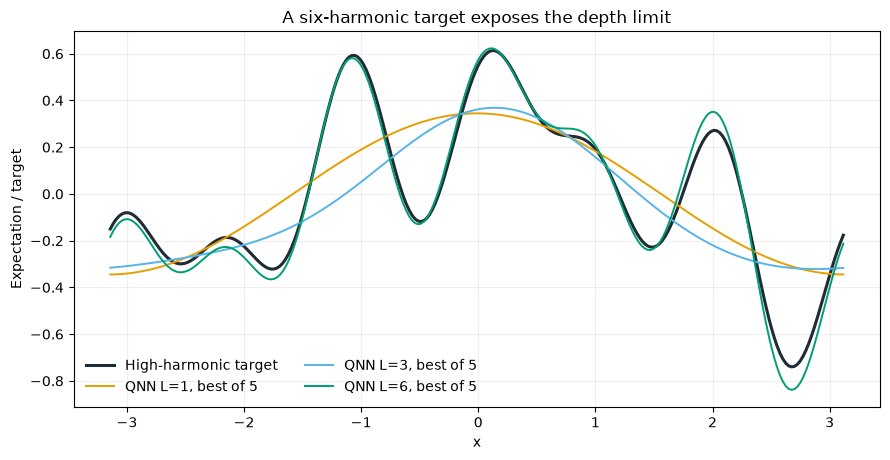

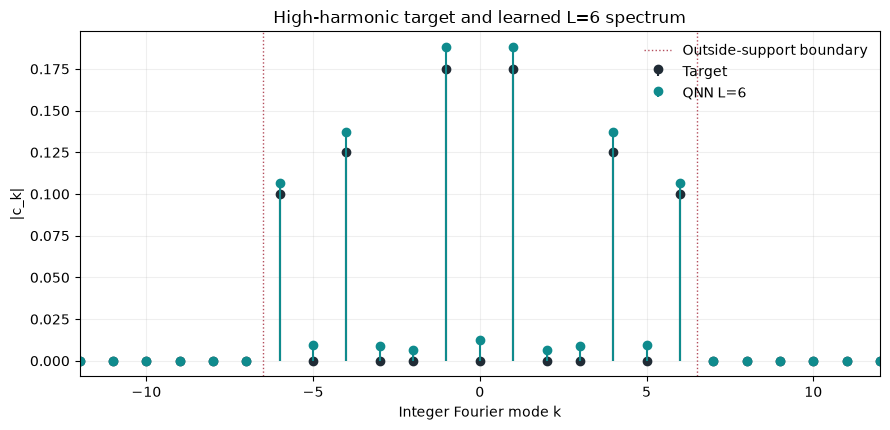

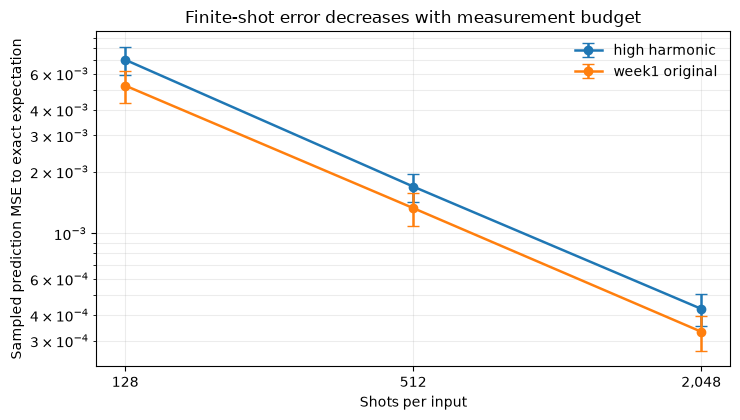

Saved advancement outputs to: C:\Users\Teacher\Desktop\qml\qnn-fourier-spectrum\outputs\week1Advancement

Layer summary:
         target  layers  parameters  qnn_grid_mse_mean  qnn_grid_mse_sd  train_mse_mean  fourier_KL_mse  outside_modes_256_total  outside_modes_512_total
 high_harmonic       1           2           0.051271     1.321226e-12        0.053399    5.127122e-02                        0                        0
 high_harmonic       2           4           0.118468     2.441850e-03        0.110755    5.337374e-02                        0                        0
 high_harmonic       3           6           0.081278     5.538888e-02        0.067763    5.536454e-02                        0                        0
 high_harmonic       4           8           0.043101     8.394318e-03        0.041927    2.050294e-02                        0                        0
 high_harmonic       5          10           0.032155     8.963217e-03        0.027440    2.096070e-02           

In [7]:
summary_df = run_df.groupby(["target", "layers"], as_index=False).agg(
    parameters=("parameters", "first"),
    qnn_grid_mse_mean=("grid_mse", "mean"),
    qnn_grid_mse_sd=("grid_mse", "std"),
    train_mse_mean=("train_mse", "mean"),
    fourier_KL_mse=("fourier_KL_mse", "mean"),
    outside_modes_256_total=("grid256_outside_count", "sum"),
    outside_modes_512_total=("grid512_outside_count", "sum"),
)
summary_df.to_csv(OUT / "advancement_layer_summary.csv", index=False)

resource_df = pd.DataFrame([
    {"layers": L, "qubits": 1, "data_encoding_gates": L,
     "trainable_single_qubit_gates": 2*L, "trainable_angles": 2*L,
     "two_qubit_gates": 0, "serial_gate_depth": 3*L,
     "statevector_dimension": 2}
    for L in LAYERS
])
resource_df.to_csv(OUT / "advancement_circuit_resources.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=False)
for ax, target_name, title in zip(axes, targets, ("Original Week 1 target", "High-harmonic challenge")):
    view = summary_df[summary_df["target"] == target_name]
    ax.errorbar(view["layers"], view["qnn_grid_mse_mean"], yerr=view["qnn_grid_mse_sd"],
                marker="o", capsize=4, linewidth=1.8, color="#0F8B8D", label="QNN mean +/- SD")
    ax.plot(view["layers"], view["fourier_KL_mse"], marker="s", linestyle="--",
            color="#D17A22", label="Fourier K=L baseline")
    ax.set_yscale("log")
    ax.set_xticks(LAYERS)
    ax.set_xlabel("Re-uploading layers L")
    ax.set_title(title)
    ax.grid(alpha=0.24, which="both")
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("Dense-grid MSE (log scale)")
fig.suptitle("QNN depth, fit quality, and support-matched reference", y=1.02, fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "advancement_layer_sweep.png", dpi=190, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.7))
ax.plot(x_grid, y_high_grid, color="#202B35", linewidth=2.2, label="High-harmonic target")
for layers, color in [(1, "#E69F00"), (3, "#56B4E9"), (6, "#009E73")]:
    subset = run_df[(run_df.target == "high_harmonic") & (run_df.layers == layers)].sort_values("grid_mse")
    row = subset.iloc[0]
    key = f"high_harmonic_L{layers}_seed{int(row.seed)}_grid256"
    ax.plot(x_grid, predictions[key], color=color, linewidth=1.4,
            label=f"QNN L={layers}, best of 5")
ax.set_xlabel("x")
ax.set_ylabel("Expectation / target")
ax.set_title("A six-harmonic target exposes the depth limit")
ax.grid(alpha=0.2)
ax.legend(frameon=False, ncol=2)
fig.tight_layout()
fig.savefig(FIG / "advancement_high_harmonic_fits.png", dpi=190, bbox_inches="tight")
plt.show()

rep_key = "high_harmonic_L6_seed" + str(int(run_df[(run_df.target == "high_harmonic") & (run_df.layers == 6)].sort_values("grid_mse").iloc[0].seed))
rep = predictions[rep_key + "_grid512"]
spec = spectrum_summary(rep, 6)
target_coeff = np.fft.fftshift(np.fft.fft(y_high_grid_512) / len(y_high_grid_512))
target_modes = np.rint(np.fft.fftshift(np.fft.fftfreq(len(y_high_grid_512), d=1/len(y_high_grid_512)))).astype(int)
fig, ax = plt.subplots(figsize=(9, 4.4))
target_marker, target_stems, _ = ax.stem(target_modes, np.abs(target_coeff), linefmt="k-", markerfmt="ko", basefmt=" ", label="Target")
target_marker.set_color("#202B35"); target_stems.set_color("#202B35")
qnn_marker, qnn_stems, _ = ax.stem(spec["modes"], spec["magnitudes"], linefmt="C0-", markerfmt="C0o", basefmt=" ", label="QNN L=6")
qnn_marker.set_color("#0F8B8D"); qnn_stems.set_color("#0F8B8D")
ax.axvline(-6.5, color="#B44D5C", linestyle=":", linewidth=1)
ax.axvline(6.5, color="#B44D5C", linestyle=":", linewidth=1, label="Outside-support boundary")
ax.set_xlim(-12, 12)
ax.set_xlabel("Integer Fourier mode k")
ax.set_ylabel("|c_k|")
ax.set_title("High-harmonic target and learned L=6 spectrum")
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "advancement_fourier_spectrum.png", dpi=190, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4.3))
for target_name, group in shot_summary.groupby("target"):
    ax.errorbar(group["shots_per_input"], group["mse_exact_mean"], yerr=group["mse_exact_sd"],
                marker="o", capsize=4, linewidth=1.8, label=target_name.replace("_", " "))
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks([128, 512, 2048], labels=["128", "512", "2,048"])
ax.set_xlabel("Shots per input")
ax.set_ylabel("Sampled prediction MSE to exact expectation")
ax.set_title("Finite-shot error decreases with measurement budget")
ax.grid(alpha=0.24, which="both")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "advancement_finite_shot_error.png", dpi=190, bbox_inches="tight")
plt.show()

config = {
    "task": "Week 1 advancement: re-uploading depth, high-harmonic target, gate-axis ablation, and finite-shot robustness",
    "student": "Rana Muhammad Hamza",
    "roll_number": "25280103",
    "root_seed": SEED,
    "initialization_seeds": list(INITIALIZATION_SEEDS),
    "layers": list(LAYERS),
    "training_samples": int(len(x_train)),
    "evaluation_grid": 256,
    "spectrum_refinement_grid": 512,
    "optimizer": "full-batch Adam with exact parameter-shift gradients",
    "learning_rate": LEARNING_RATE,
    "max_steps": MAX_STEPS,
    "circuit": "RY(x), trainable RZ(theta_z), RY(theta_y), measure expectation Z",
    "shots": {"grid_points": 64, "repeats": 20, "budgets": [128, 512, 2048]},
    "spectrum_threshold": "max(1e-6, 0.01*c_max)",
    "data_source": str(SOURCE_NPZ.relative_to(ROOT)),
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit_learn": sklearn.__version__,
}
(OUT / "advancement_run_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")

print("Saved advancement outputs to:", OUT.resolve())
print("\nLayer summary:\n", summary_df.to_string(index=False))
print("\nGate-axis ablation:\n", axis_df.groupby("data_axis")["grid_mse"].agg(["mean", "std"]).to_string())
print("\nAll 256/512 spectrum support checks passed:", int(run_df["grid256_outside_count"].sum() + run_df["grid512_outside_count"].sum()) == 0)
